In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering

from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
# Load Iris dataset
iris = load_iris()

# Select two features
X = iris.data[:, [0, 2]]

# Convert into DataFrame
df = pd.DataFrame(X, columns=['Sepal Length', 'Petal Length'])

print("First five rows:")
print(df.head())

First five rows:
   Sepal Length  Petal Length
0           5.1           1.4
1           4.9           1.4
2           4.7           1.3
3           4.6           1.5
4           5.0           1.4


In [3]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled Data:")
print(X_scaled[:5])

Scaled Data:
[[-0.90068117 -1.34022653]
 [-1.14301691 -1.34022653]
 [-1.38535265 -1.39706395]
 [-1.50652052 -1.2833891 ]
 [-1.02184904 -1.34022653]]


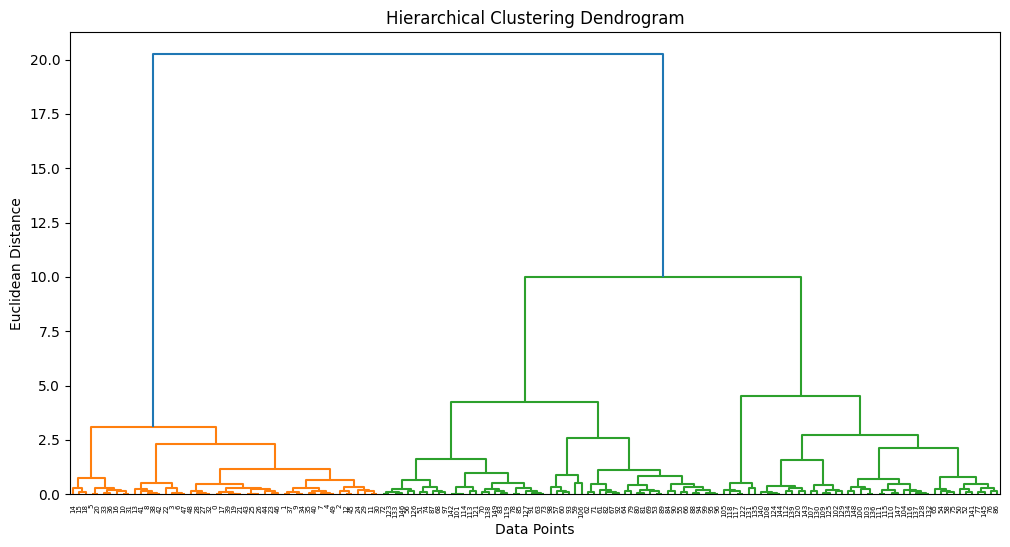

In [4]:
# Perform hierarchical clustering
linked = linkage(X_scaled, method='ward')

# Plot dendrogram
plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('Euclidean Distance')

plt.show()

In [5]:
# Create Agglomerative Clustering model
hc = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

# Fit the model
y_hc = hc.fit_predict(X_scaled)

# Add cluster labels
df['Cluster'] = y_hc

print("Clustered Dataset:")
print(df.head(10))

Clustered Dataset:
   Sepal Length  Petal Length  Cluster
0           5.1           1.4        1
1           4.9           1.4        1
2           4.7           1.3        1
3           4.6           1.5        1
4           5.0           1.4        1
5           5.4           1.7        1
6           4.6           1.4        1
7           5.0           1.5        1
8           4.4           1.4        1
9           4.9           1.5        1


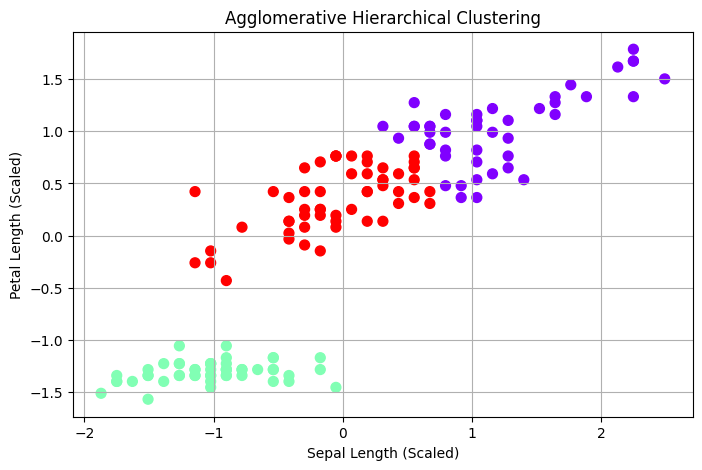

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y_hc,
    cmap='rainbow',
    s=50
)

plt.title('Agglomerative Hierarchical Clustering')
plt.xlabel('Sepal Length (Scaled)')
plt.ylabel('Petal Length (Scaled)')

plt.grid(True)
plt.show()